# StockSense — Entrenamiento del modelo de predicción de demanda

## 1. Introducción al problema

StockSense necesita estimar **cuántas unidades de un producto se venderán cada día** para calcular cuándo se agotará el inventario y cuánto reponer.

Se plantea un problema de **regresión supervisada**:

* **Variable objetivo:** `units_sold` (unidades vendidas en un día).
* **Algoritmo:** regresión lineal (`sklearn.linear_model.LinearRegression`) dentro de un `Pipeline` que incluye el preprocesamiento.
* **Uso posterior:** la aplicación Flask carga el modelo exportado (`models/demand_model.joblib`) y lo usa para predecir los próximos días de forma recursiva. **La aplicación nunca reentrena el modelo.**

> **Aviso académico:** todos los datos de este notebook son **sintéticos**, generados con reglas comerciales simuladas y semillas aleatorias reproducibles. Los resultados representan un experimento académico y **no** un modelo validado con ventas reales.

### Ventas observadas vs. demanda
La **demanda** es lo que los clientes quieren comprar; la **venta observada** es lo que efectivamente se vendió. Si el producto se agota, la venta observada es menor que la demanda (venta *censurada*). El simulador genera primero una demanda latente y luego registra `units_sold = min(demanda, stock disponible)`. Para que el modelo aprenda la demanda y no las limitaciones del inventario, en la etapa de limpieza se excluyen los días con quiebre de stock y **no** se usa el inventario disponible como variable predictora.

In [1]:
import sys, json, platform
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# El notebook vive en notebooks/: se agrega la raíz del proyecto al path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from ml.generate_dataset import generate_dataset, DEFAULT_SEED
from ml.features import (TARGET, NUMERIC_FEATURES, CATEGORICAL_FEATURES, INPUT_FEATURES,
                         INTERACTION_FEATURES, add_interaction_features)
from ml.forecasting import recursive_forecast

%matplotlib inline
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 4.5)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
RANDOM_SEED = DEFAULT_SEED
print("Python", platform.python_version(), "| scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

Python 3.12.1 | scikit-learn 1.9.1 | pandas 3.1.1


## 2. Generación o carga del dataset sintético

El dataset se genera con `ml/generate_dataset.py` (semilla 42). Si `data/synthetic_sales.csv` ya existe se carga; en cualquier caso se comprueba que **regenerarlo con la misma semilla produce exactamente los mismos datos** (reproducibilidad).

Reglas del simulador (`ml/simulation.py`):

| Regla | Implementación |
|---|---|
| Rotación | alta (25–60 u/día), media (8–20), baja (1–5) |
| Día de la semana | perfil lunes–domingo + aumento de fin de semana según categoría |
| Temporada | factores mensuales (enero bajo, junio–julio y noviembre–diciembre altos) |
| Tendencia | crecimiento o decrecimiento anual entre −10 % y +25 % |
| Precio | cambios ocasionales (±15 %) con elasticidad entre 0.8 y 1.8 |
| Promociones | descuentos del 10 % al 40 %; cada punto de descuento aumenta la demanda 2.5 % |
| Ruido | Gamma-Poisson (variabilidad controlada) |
| Inventario | política de punto de reorden con pedidos que a veces llegan tarde (quiebres) |

In [2]:
DATA_PATH = PROJECT_ROOT / "data" / "synthetic_sales.csv"
regenerated = generate_dataset(seed=RANDOM_SEED)

if DATA_PATH.exists():
    df_raw = pd.read_csv(DATA_PATH)
    pd.testing.assert_frame_equal(regenerated, df_raw, check_dtype=False)
    print("Dataset cargado desde CSV y verificado: coincide con la generación de semilla", RANDOM_SEED)
else:
    df_raw = regenerated
    DATA_PATH.parent.mkdir(exist_ok=True)
    df_raw.to_csv(DATA_PATH, index=False)
    print("Dataset generado y guardado en", DATA_PATH)

print(f"Registros: {len(df_raw):,} | Productos: {df_raw.product_id.nunique()} | "
      f"Periodo: {df_raw.date.min()} a {df_raw.date.max()}")
df_raw.head()

Dataset cargado desde CSV y verificado: coincide con la generación de semilla 42
Registros: 35,000 | Productos: 50 | Periodo: 2024-01-31 a 2025-12-30


,product_id,date,category,rotation,day_of_week,month,price,units_available,promotion,discount_percentage,previous_sales,average_sales_7d,average_sales_30d,stockout,units_sold
0,1,2024-01-31,Bebidas,baja,2,1,"3,400.000",30,0,0.000,0.000,0.429,0.833,0,2
1,1,2024-02-01,Bebidas,baja,3,2,"3,400.000",28,0,0.000,2.000,0.714,0.867,0,1
2,1,2024-02-02,Bebidas,baja,4,2,"3,400.000",27,0,0.000,1.000,0.571,0.900,0,2
3,1,2024-02-03,Bebidas,baja,5,2,"3,400.000",25,0,0.000,2.000,0.857,0.967,0,1
4,1,2024-02-04,Bebidas,baja,6,2,"3,400.000",24,0,0.000,1.000,0.857,0.933,0,1


## 3. Descripción de las variables

| Variable | Tipo | Descripción |
|---|---|---|
| `product_id` | entero | Identificador del producto ficticio (1–50) |
| `date` | fecha | Día del registro |
| `category` | categórica | Bebidas, Snacks, Lácteos, Abarrotes, Aseo, Cuidado personal |
| `rotation` | categórica | Nivel de rotación (alta, media, baja). **Parámetro oculto del simulador**: solo se usa para el análisis |
| `day_of_week` | entero 0–6 | 0 = lunes … 6 = domingo |
| `month` | entero 1–12 | Mes del año |
| `price` | real | Precio de lista en pesos colombianos (COP) |
| `units_available` | entero | Stock disponible al inicio del día |
| `promotion` | 0/1 | Indica si hubo promoción |
| `discount_percentage` | real | Porcentaje de descuento (0 si no hay promoción) |
| `previous_sales` | real | Unidades vendidas el día anterior |
| `average_sales_7d` | real | Promedio de ventas de los 7 días anteriores |
| `average_sales_30d` | real | Promedio de ventas de los 30 días anteriores |
| `stockout` | 0/1 | Se vendió todo el stock disponible (venta censurada) |
| `units_sold` | entero | **Variable objetivo**: unidades vendidas |

Los promedios móviles se calculan con `shift(1)`: el valor de un día solo usa información de días anteriores, de modo que no hay fuga de información del objetivo.

In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 35000 entries, 0 to 34999
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   product_id           35000 non-null  int64  
 1   date                 35000 non-null  str    
 2   category             35000 non-null  str    
 3   rotation             35000 non-null  str    
 4   day_of_week          35000 non-null  int64  
 5   month                35000 non-null  int64  
 6   price                35000 non-null  float64
 7   units_available      35000 non-null  int64  
 8   promotion            35000 non-null  int64  
 9   discount_percentage  35000 non-null  float64
 10  previous_sales       35000 non-null  float64
 11  average_sales_7d     35000 non-null  float64
 12  average_sales_30d    35000 non-null  float64
 13  stockout             35000 non-null  int64  
 14  units_sold           35000 non-null  int64  
dtypes: float64(5), int64(7), str(3)
memory usage: 4

## 4. Análisis exploratorio

In [4]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
product_id,"35,000.000",25.500,14.431,1.000,13.000,25.500,38.000,50.000
day_of_week,"35,000.000",3.000,2.000,0.000,1.000,3.000,5.000,6.000
month,"35,000.000",6.749,3.320,1.000,4.000,7.000,10.000,12.000
price,"35,000.000","9,823.254","6,456.496","1,650.000","5,300.000","8,700.000","12,750.000","32,300.000"
units_available,"35,000.000",321.646,391.126,0.000,65.000,175.000,403.000,"2,791.000"
promotion,"35,000.000",0.131,0.338,0.000,0.000,0.000,0.000,1.000
discount_percentage,"35,000.000",2.938,8.340,0.000,0.000,0.000,0.000,40.000
previous_sales,"35,000.000",19.921,25.023,0.000,4.000,12.000,25.000,369.000
average_sales_7d,"35,000.000",19.872,22.476,0.000,4.286,13.000,24.286,234.571
average_sales_30d,"35,000.000",19.711,21.413,0.733,4.300,13.400,23.033,159.133


In [5]:
summary = df_raw.groupby("rotation").agg(
    productos=("product_id", "nunique"),
    ventas_promedio=("units_sold", "mean"),
    ventas_desviacion=("units_sold", "std"),
    precio_promedio=("price", "mean"),
).reindex(["alta", "media", "baja"])
summary

,productos,ventas_promedio,ventas_desviacion,precio_promedio
rotation,,,,
alta,12,52.138,31.974,"11,021.351"
media,20,15.348,7.945,"10,329.418"
baja,18,3.563,2.676,"8,462.119"


In [6]:
df_raw.groupby("category").agg(productos=("product_id", "nunique"),
                               ventas_promedio=("units_sold", "mean"),
                               precio_promedio=("price", "mean"),
                               dias_promocion=("promotion", "mean")).round(3)

,productos,ventas_promedio,precio_promedio,dias_promocion
category,,,,
Abarrotes,8,20.621,"12,730.821",0.141
Aseo,8,20.509,"13,615.607",0.134
Bebidas,9,10.418,"5,472.468",0.145
Cuidado personal,8,21.832,"16,018.848",0.128
Lácteos,8,22.930,"8,194.616",0.133
Snacks,9,23.983,"4,159.040",0.108


## 5. Identificación de valores nulos y duplicados

In [7]:
print("Valores nulos por columna:")
print(df_raw.isna().sum().to_string())
print("\nFilas completamente duplicadas:", df_raw.duplicated().sum())
print("Duplicados por (product_id, date):", df_raw.duplicated(subset=["product_id", "date"]).sum())

Valores nulos por columna:
product_id             0
date                   0
category               0
rotation               0
day_of_week            0
month                  0
price                  0
units_available        0
promotion              0
discount_percentage    0
previous_sales         0
average_sales_7d       0
average_sales_30d      0
stockout               0
units_sold             0

Filas completamente duplicadas: 0
Duplicados por (product_id, date): 0


No hay nulos ni duplicados porque el generador elimina los primeros 30 días de cada producto (no tienen promedio de 30 días) y produce un único registro por producto y día. En datos reales esta verificación es imprescindible.

## 6. Limpieza y preparación

1. Conversión de `date` a tipo fecha.
2. Verificación de rangos válidos (sin ventas ni precios negativos, descuento entre 0 y 100).
3. **Exclusión de días con quiebre de stock** (`stockout = 1`): en esos días la venta observada es menor que la demanda real; incluirlos enseñaría al modelo a predecir el límite del inventario y no la demanda.

In [8]:
df = df_raw.copy()
df["date"] = pd.to_datetime(df["date"])

assert (df["units_sold"] >= 0).all() and (df["price"] > 0).all()
assert df["discount_percentage"].between(0, 100).all()
assert (df.loc[df.promotion == 0, "discount_percentage"] == 0).all()

stockout_rows = int(df["stockout"].sum())
print(f"Días con quiebre de stock (ventas censuradas): {stockout_rows} ({stockout_rows / len(df):.2%})")
df_model = df[df["stockout"] == 0].copy()
print(f"Registros disponibles para modelar: {len(df_model):,}")

Días con quiebre de stock (ventas censuradas): 292 (0.83%)
Registros disponibles para modelar: 34,708


## 7. Análisis de correlaciones

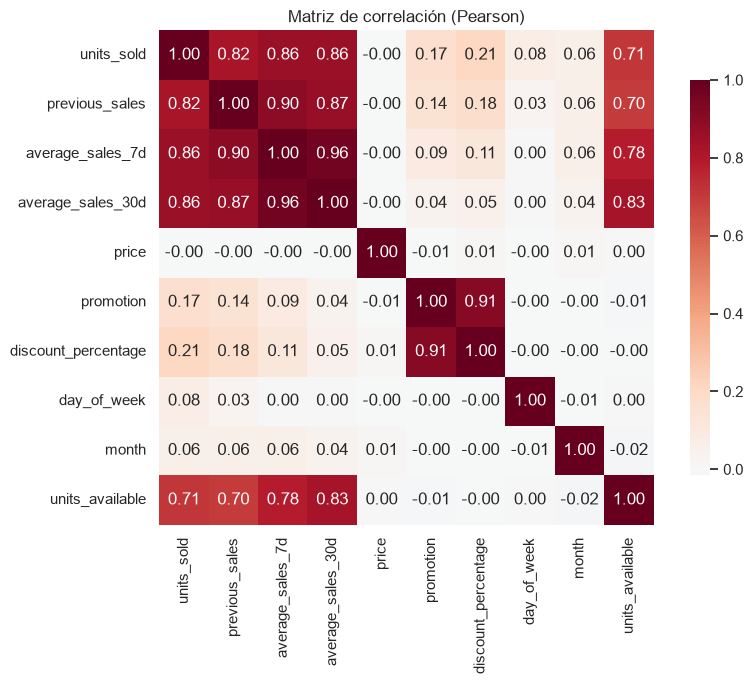

units_sold             1.000
average_sales_7d       0.863
average_sales_30d      0.859
previous_sales         0.821
units_available        0.713
discount_percentage    0.206
promotion              0.170
day_of_week            0.075
month                  0.060
price                 -0.002
Name: units_sold, dtype: float64

In [9]:
numeric_columns = ["units_sold", "previous_sales", "average_sales_7d", "average_sales_30d",
                   "price", "promotion", "discount_percentage", "day_of_week", "month", "units_available"]
correlation = df_model[numeric_columns].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="RdBu_r", center=0, square=True, cbar_kws={"shrink": .8})
plt.title("Matriz de correlación (Pearson)")
plt.tight_layout(); plt.show()
correlation["units_sold"].sort_values(ascending=False)

**Lectura:** las variables de historial (`previous_sales`, promedios de 7 y 30 días) tienen la correlación más alta con `units_sold`: el nivel de ventas reciente es el mejor indicador del nivel futuro. El descuento tiene correlación positiva moderada. La correlación del precio es casi nula porque mezcla productos de precios muy distintos; su efecto real (elasticidad) ocurre *dentro* de cada producto y es pequeño. `units_available` está correlacionada con las ventas porque la política de inventario repone más stock a los productos que más venden; por eso **no** se usa como predictor: el modelo aprendería la política de reposición y no la demanda.

## 8. Visualizaciones

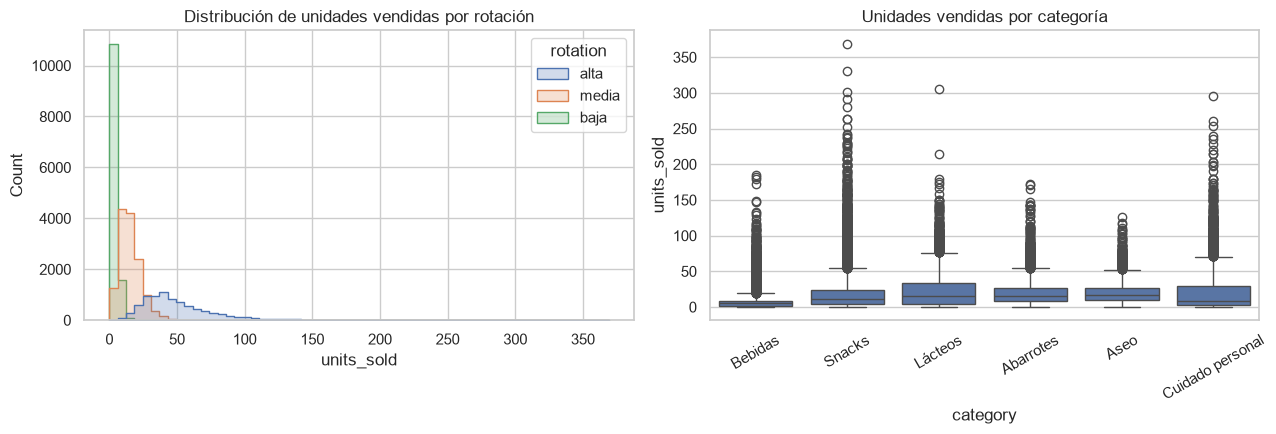

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(data=df_model, x="units_sold", hue="rotation", hue_order=["alta", "media", "baja"],
             bins=60, element="step", ax=axes[0])
axes[0].set_title("Distribución de unidades vendidas por rotación")
sns.boxplot(data=df_model, x="category", y="units_sold", ax=axes[1])
axes[1].set_title("Unidades vendidas por categoría"); axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

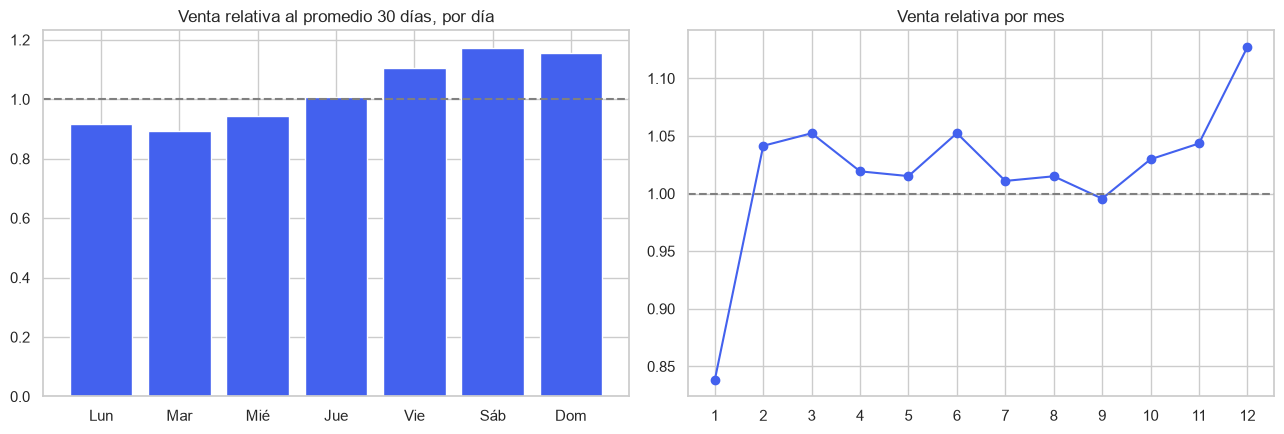

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
day_names = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
relative = df_model.assign(relative_sales=df_model.units_sold / df_model.average_sales_30d.clip(lower=0.5))
by_day = relative.groupby("day_of_week")["relative_sales"].mean()
axes[0].bar(day_names, by_day.values, color="#4361ee")
axes[0].axhline(1, color="gray", ls="--"); axes[0].set_title("Venta relativa al promedio 30 días, por día")
by_month = relative.groupby("month")["relative_sales"].mean()
axes[1].plot(by_month.index, by_month.values, marker="o", color="#4361ee")
axes[1].axhline(1, color="gray", ls="--"); axes[1].set_xticks(range(1, 13))
axes[1].set_title("Venta relativa por mes")
plt.tight_layout(); plt.show()

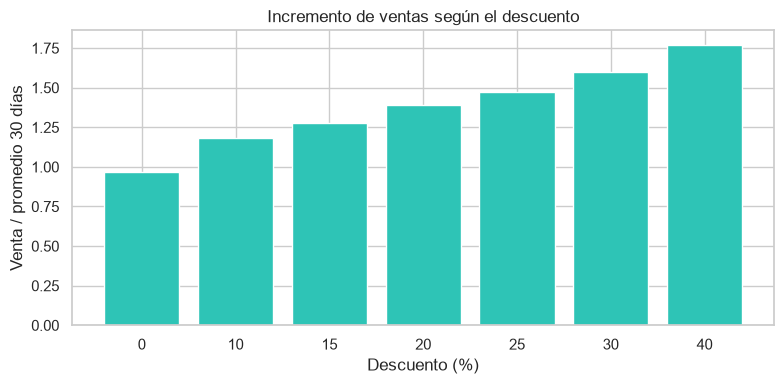

,mean,count
discount_percentage,,
0.000,0.968,30205
10.000,1.181,859
15.000,1.276,835
20.000,1.390,763
25.000,1.475,795
30.000,1.598,614
40.000,1.773,637


In [12]:
promo_effect = relative.groupby("discount_percentage")["relative_sales"].agg(["mean", "count"])
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(promo_effect.index.astype(int).astype(str), promo_effect["mean"], color="#2ec4b6")
ax.set_xlabel("Descuento (%)"); ax.set_ylabel("Venta / promedio 30 días")
ax.set_title("Incremento de ventas según el descuento")
plt.tight_layout(); plt.show()
promo_effect

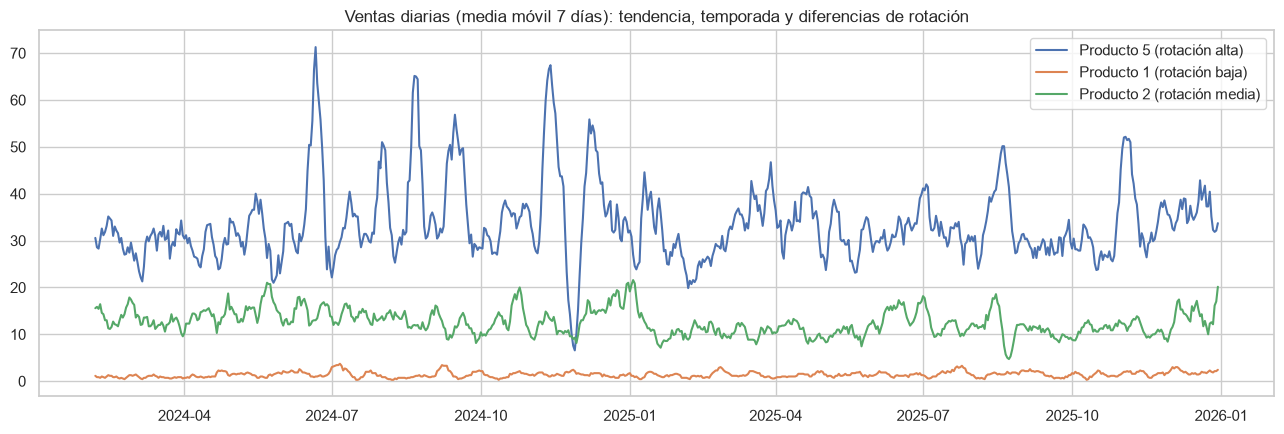

In [13]:
sample_products = (df_model.groupby(["rotation", "product_id"]).size().reset_index()
                   .groupby("rotation").first()["product_id"])
fig, ax = plt.subplots(figsize=(13, 4.5))
for rotation, product_id in sample_products.items():
    series = df_raw[df_raw.product_id == product_id].assign(date=lambda d: pd.to_datetime(d.date))
    ax.plot(series.date, series.units_sold.rolling(7).mean(), label=f"Producto {product_id} (rotación {rotation})")
ax.set_title("Ventas diarias (media móvil 7 días): tendencia, temporada y diferencias de rotación")
ax.legend(); plt.tight_layout(); plt.show()

Las gráficas confirman que los datos tienen la lógica comercial esperada: los fines de semana venden más, diciembre es el pico y enero el valle, los descuentos mayores generan más ventas, y los tres niveles de rotación están bien diferenciados. Hay tendencias distintas por producto.

## 9. Selección de variables predictoras

| Variable | ¿Se usa? | Justificación |
|---|---|---|
| `price` | Sí (numérica) | Afecta la demanda (elasticidad) |
| `discount_percentage`, `promotion` | Sí | Las promociones aumentan la demanda; el simulador de escenarios las modifica |
| `previous_sales`, `average_sales_7d`, `average_sales_30d` | Sí | Resumen el nivel reciente de demanda del producto |
| `day_of_week`, `month` | Sí (OneHotEncoder) | Su efecto no es lineal (sábado no es "6 veces lunes"); se codifican como categorías |
| `category` | Sí (OneHotEncoder) | Característica del producto disponible también para productos nuevos |
| `discount_x_avg30`, `weekend_x_avg30` | Sí (derivadas en el Pipeline) | Permiten efectos **proporcionales** al nivel de ventas del producto |
| `units_available` | **No** | Es una decisión de inventario, no demanda; usarla causaría que el modelo aprenda la política de reposición |
| `stockout` | **No** | Se usa solo para limpiar; no se conoce de antemano |
| `rotation` | **No** | Parámetro oculto del simulador; en la aplicación no existe |
| `product_id` | **No** (se evalúa abajo) | Un OneHot por producto no sirve para productos nuevos registrados en la aplicación |

## 10. Separación de entrenamiento, validación y prueba

Se usa una **separación temporal** (no aleatoria): el modelo se entrena con el pasado y se evalúa con fechas posteriores, como ocurriría en producción. Una separación aleatoria filtraría información del futuro (por ejemplo, promedios móviles que comparten días con el conjunto de prueba).

* **Entrenamiento:** hasta el 30-abr-2025
* **Validación:** 01-may-2025 a 31-ago-2025 (selección del modelo)
* **Prueba:** 01-sep-2025 en adelante (evaluación final; solo se usa una vez)

In [14]:
VALIDATION_START, TEST_START = pd.Timestamp("2025-05-01"), pd.Timestamp("2025-09-01")
train = df_model[df_model.date < VALIDATION_START]
validation = df_model[(df_model.date >= VALIDATION_START) & (df_model.date < TEST_START)]
test = df_model[df_model.date >= TEST_START]

split_summary = pd.DataFrame({
    "registros": [len(train), len(validation), len(test)],
    "desde": [train.date.min().date(), validation.date.min().date(), test.date.min().date()],
    "hasta": [train.date.max().date(), validation.date.max().date(), test.date.max().date()],
}, index=["entrenamiento", "validación", "prueba"])
split_summary["porcentaje"] = (split_summary.registros / len(df_model) * 100).round(1)
split_summary

,registros,desde,hasta,porcentaje
entrenamiento,22648,2024-01-31,2025-04-30,65.300
validación,6063,2025-05-01,2025-08-31,17.500
prueba,5997,2025-09-01,2025-12-30,17.300


## 11. Entrenamiento de la regresión lineal

Todo el preprocesamiento vive dentro de un `Pipeline` de Scikit-learn, de modo que se ajusta **solo con los datos de entrenamiento** (el `StandardScaler` aprende media y desviación únicamente del entrenamiento) y se exporta junto con el modelo:

1. `FunctionTransformer(add_interaction_features)`: crea las interacciones.
2. `ColumnTransformer`: `StandardScaler` para numéricas y `OneHotEncoder(drop="first", handle_unknown="ignore")` para categóricas.
3. `LinearRegression`: mínimos cuadrados ordinarios.

Se comparan en el conjunto de **validación**:
* **Línea base:** predecir el promedio de los últimos 7 días (sin modelo).
* **A:** regresión con variables numéricas.
* **B:** A + variables categóricas con OneHotEncoder.
* **C:** B + interacciones.
* **D:** C + OneHot de `product_id` (para evaluar si conviene incluir el identificador).

In [15]:
def build_pipeline(numeric, categorical, interactions):
    steps = []
    numeric = list(numeric)
    if interactions:
        steps.append(("interactions", FunctionTransformer(add_interaction_features)))
        numeric += INTERACTION_FEATURES
    transformers = [("numeric", StandardScaler(), numeric)]
    if categorical:
        transformers.append(("categorical", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical))
    steps.append(("preprocess", ColumnTransformer(transformers)))
    steps.append(("regressor", LinearRegression()))
    return Pipeline(steps)


def metrics(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "R2": r2_score(y_true, y_pred)}


candidates = {
    "A: numéricas": (NUMERIC_FEATURES, [], False),
    "B: + OneHot (día, mes, categoría)": (NUMERIC_FEATURES, CATEGORICAL_FEATURES, False),
    "C: B + interacciones": (NUMERIC_FEATURES, CATEGORICAL_FEATURES, True),
    "D: C + product_id": (NUMERIC_FEATURES, CATEGORICAL_FEATURES + ["product_id"], True),
}
results = {"Línea base (promedio 7 días)": metrics(validation[TARGET], validation["average_sales_7d"])}
for name, (numeric, categorical, interactions) in candidates.items():
    columns = list(numeric) + list(categorical)
    pipeline = build_pipeline(numeric, categorical, interactions).fit(train[columns], train[TARGET])
    predictions = np.clip(pipeline.predict(validation[columns]), 0, None)
    results[name] = metrics(validation[TARGET], predictions)

comparison = pd.DataFrame(results).T
comparison

,MAE,RMSE,R2
Línea base (promedio 7 días),7.450,14.440,0.731
A: numéricas,7.053,13.040,0.780
"B: + OneHot (día, mes, categoría)",7.033,12.917,0.784
C: B + interacciones,6.550,11.746,0.822
D: C + product_id,6.304,11.572,0.827


**Selección:** se elige el **modelo C**. Supera claramente a la línea base y a los modelos A y B. El modelo D mejora muy poco frente a C, pero depende del identificador de cada producto: no podría predecir productos nuevos creados en la aplicación (su OneHot sería desconocido). C usa características del producto (categoría y nivel de ventas reciente) y generaliza a cualquier producto.

Tras seleccionar el modelo con validación, se reentrena C con **entrenamiento + validación** (más historia, incluido un diciembre completo) y se evalúa **una sola vez** en el conjunto de prueba.

In [16]:
SELECTED_NUMERIC, SELECTED_CATEGORICAL = NUMERIC_FEATURES, CATEGORICAL_FEATURES
train_full = pd.concat([train, validation])
model = build_pipeline(SELECTED_NUMERIC, SELECTED_CATEGORICAL, interactions=True)
model.fit(train_full[INPUT_FEATURES], train_full[TARGET])

validation_metrics = results["C: B + interacciones"]
test_predictions = np.clip(model.predict(test[INPUT_FEATURES]), 0, None)
test_metrics = metrics(test[TARGET], test_predictions)
print("Modelo entrenado con", f"{len(train_full):,}", "registros")

Modelo entrenado con 28,711 registros


## 12. Evaluación del modelo

* **MAE** (error absoluto medio): en promedio, cuántas unidades se equivoca la predicción diaria.
* **RMSE** (raíz del error cuadrático medio): como el MAE, pero penaliza más los errores grandes.
* **R²** (coeficiente de determinación): proporción de la variabilidad de las ventas explicada por el modelo (1 = perfecto, 0 = igual que predecir el promedio).

In [17]:
test_eval = test.assign(prediction=test_predictions, abs_error=np.abs(test[TARGET] - test_predictions))
print("Métricas en PRUEBA (datos no usados para entrenar ni seleccionar):")
for name, value in test_metrics.items():
    print(f"  {name:5s} = {value:.4f}")
print(f"\nVenta media en prueba: {test[TARGET].mean():.2f} unidades/día")
print(f"MAE relativo a la venta media: {test_metrics['MAE'] / test[TARGET].mean():.1%}")

by_rotation = test_eval.groupby("rotation").apply(
    lambda g: pd.Series({"registros": len(g), "venta_media": g[TARGET].mean(),
                         "MAE": g.abs_error.mean(),
                         "MAE_relativo": g.abs_error.mean() / g[TARGET].mean(),
                         "R2": r2_score(g[TARGET], g.prediction)}), include_groups=False
).reindex(["alta", "media", "baja"])
by_rotation

Métricas en PRUEBA (datos no usados para entrenar ni seleccionar):
  MAE   = 6.6272
  RMSE  = 11.8370
  R2    = 0.8191

Venta media en prueba: 21.79 unidades/día
MAE relativo a la venta media: 30.4%


,registros,venta_media,MAE,MAE_relativo,R2
rotation,,,,,
alta,"1,436.000",58.137,15.687,0.270,0.600
media,"2,394.000",16.263,5.124,0.315,0.366
baja,"2,167.000",3.806,2.285,0.600,-0.120


## 13. Gráficas de resultados

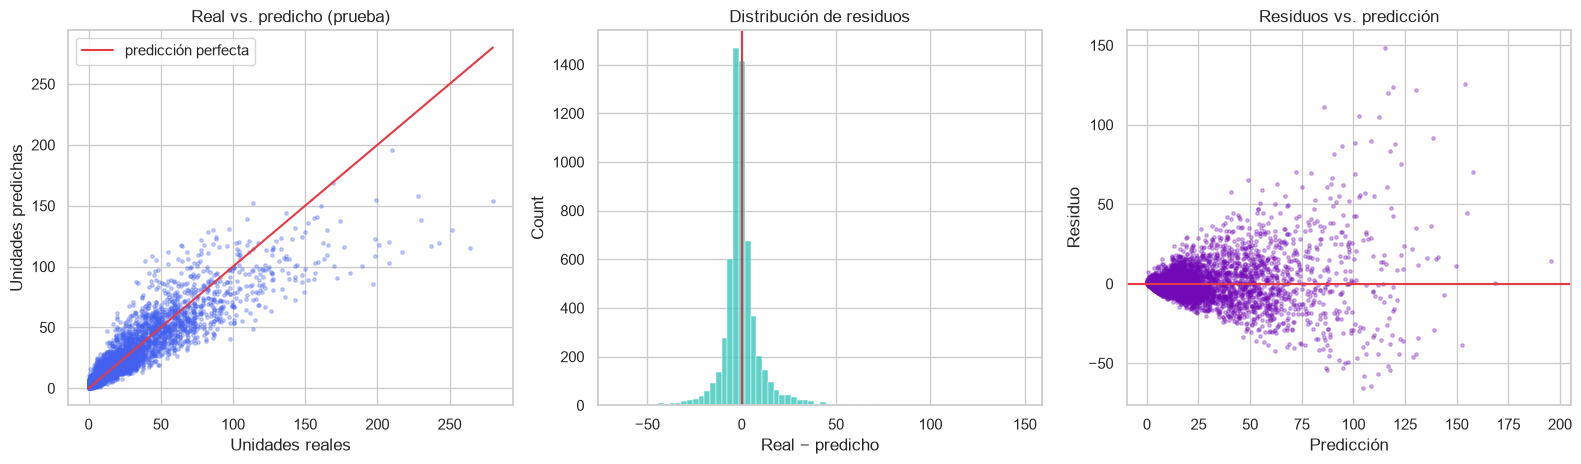

Media de residuos: 0.164 | Desviación: 11.837


In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
axes[0].scatter(test[TARGET], test_predictions, s=6, alpha=.3, color="#4361ee")
limit = max(test[TARGET].max(), test_predictions.max())
axes[0].plot([0, limit], [0, limit], color="#e63946", lw=1.5, label="predicción perfecta")
axes[0].set_xlabel("Unidades reales"); axes[0].set_ylabel("Unidades predichas")
axes[0].set_title("Real vs. predicho (prueba)"); axes[0].legend()

residuals = test[TARGET] - test_predictions
sns.histplot(residuals, bins=70, ax=axes[1], color="#2ec4b6")
axes[1].axvline(0, color="#e63946"); axes[1].set_title("Distribución de residuos")
axes[1].set_xlabel("Real − predicho")

axes[2].scatter(test_predictions, residuals, s=6, alpha=.3, color="#7209b7")
axes[2].axhline(0, color="#e63946"); axes[2].set_xlabel("Predicción"); axes[2].set_ylabel("Residuo")
axes[2].set_title("Residuos vs. predicción")
plt.tight_layout(); plt.show()
print(f"Media de residuos: {residuals.mean():.3f} | Desviación: {residuals.std():.3f}")

El gráfico de residuos contra la predicción tiene forma de **embudo**: el error crece con el volumen de ventas (heterocedasticidad). Es esperable con datos de conteo: un producto que vende 50 unidades varía más en términos absolutos que uno que vende 3. La media de los residuos cercana a cero indica que el modelo no está sesgado de forma sistemática.

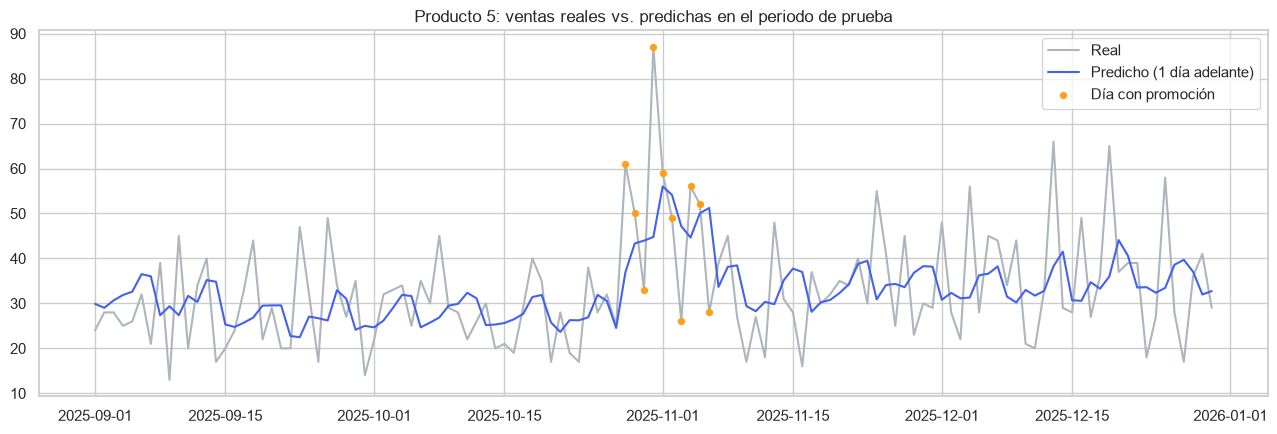

In [19]:
example_id = sample_products["alta"]
example = test_eval[test_eval.product_id == example_id]
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(example.date, example[TARGET], label="Real", color="#adb5bd")
ax.plot(example.date, example.prediction, label="Predicho (1 día adelante)", color="#4361ee")
promo_days = example[example.promotion == 1]
ax.scatter(promo_days.date, promo_days[TARGET], color="#ff9f1c", zorder=3, s=18, label="Día con promoción")
ax.set_title(f"Producto {example_id}: ventas reales vs. predichas en el periodo de prueba")
ax.legend(); plt.tight_layout(); plt.show()

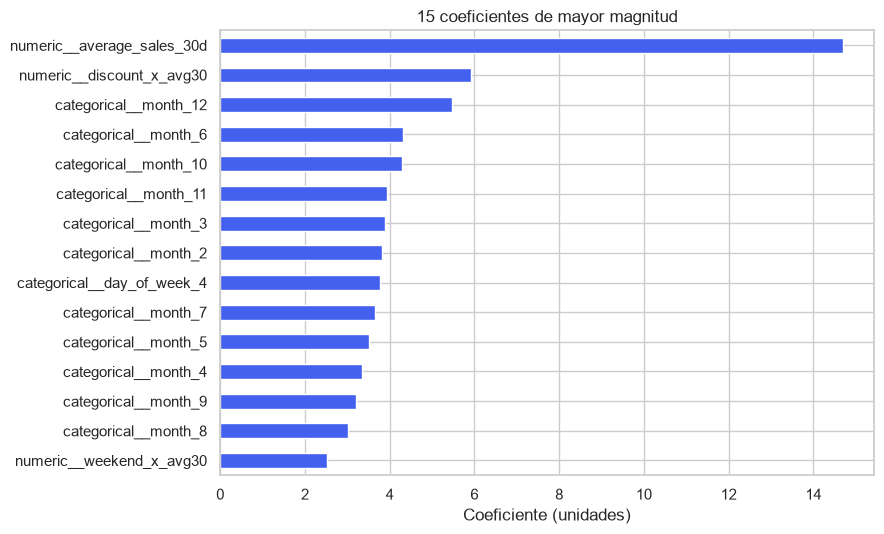

Intercepto: 14.811


In [20]:
# Coeficientes: la regresión lineal es interpretable (variables numéricas estandarizadas)
feature_names = model.named_steps["preprocess"].get_feature_names_out()
coefficients = pd.Series(model.named_steps["regressor"].coef_, index=feature_names)
top = coefficients.reindex(coefficients.abs().sort_values(ascending=False).index).head(15)
plt.figure(figsize=(9, 5.5))
top.sort_values().plot.barh(color=["#e63946" if v < 0 else "#4361ee" for v in top.sort_values()])
plt.title("15 coeficientes de mayor magnitud"); plt.xlabel("Coeficiente (unidades)")
plt.tight_layout(); plt.show()
print("Intercepto:", round(model.named_steps["regressor"].intercept_, 3))

### Evaluación del pronóstico recursivo a 30 días

La aplicación no predice un solo día: proyecta los próximos días de forma **recursiva** (`ml/forecasting.py`, el mismo código que usa Flask), con las predicciones de cada día alimentando los promedios del siguiente. Aquí se mide ese uso real: para cada producto, desde el 01-sep-2025, se pronostican 30 días usando solo la historia anterior y el calendario/precio/promociones conocidos, y se compara la **demanda acumulada** pronosticada con la real.

{'MAE_total_30d': 92.8914, 'MAPE_total_30d': 0.1425, 'R2_total_30d': 0.8359}

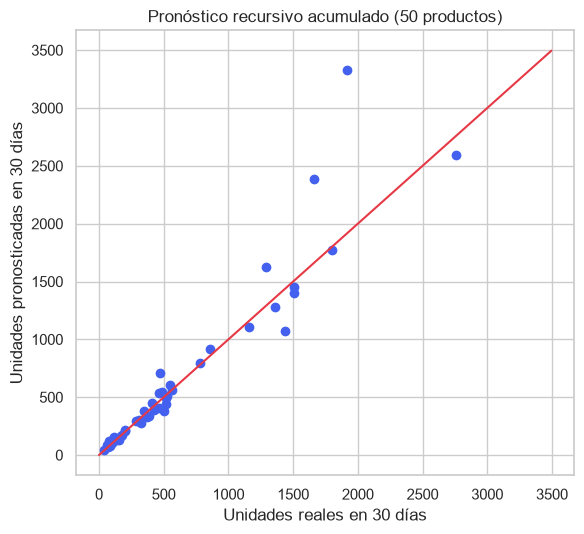

In [21]:
horizon = 30
series_list, actual_totals = [], []
for product_id, group in df.groupby("product_id"):
    history = group[group.date < TEST_START].sort_values("date")
    future = group[(group.date >= TEST_START)].sort_values("date").head(horizon)
    series_list.append({"history": history[TARGET].tolist()[-60:], "category": group.category.iloc[0],
                        "price": future.price.to_numpy(), "promotion": future.promotion.to_numpy(),
                        "discount": future.discount_percentage.to_numpy()})
    actual_totals.append(future[TARGET].sum())

forecast = recursive_forecast(model, series_list, TEST_START, horizon)
recursive_eval = pd.DataFrame({"real_30d": actual_totals, "pronosticado_30d": forecast.sum(axis=1)})
recursive_eval["error_pct"] = (recursive_eval.pronosticado_30d - recursive_eval.real_30d) / recursive_eval.real_30d
recursive_metrics = {
    "MAE_total_30d": mean_absolute_error(recursive_eval.real_30d, recursive_eval.pronosticado_30d),
    "MAPE_total_30d": float(recursive_eval.error_pct.abs().mean()),
    "R2_total_30d": r2_score(recursive_eval.real_30d, recursive_eval.pronosticado_30d),
}
print({k: round(v, 4) for k, v in recursive_metrics.items()})

fig, ax = plt.subplots(figsize=(6, 5.5))
ax.scatter(recursive_eval.real_30d, recursive_eval.pronosticado_30d, color="#4361ee")
limit = recursive_eval[["real_30d", "pronosticado_30d"]].max().max() * 1.05
ax.plot([0, limit], [0, limit], color="#e63946"); ax.set_xlabel("Unidades reales en 30 días")
ax.set_ylabel("Unidades pronosticadas en 30 días"); ax.set_title("Pronóstico recursivo acumulado (50 productos)")
plt.tight_layout(); plt.show()

## 14. Interpretación de métricas

*Valores obtenidos en la ejecución de este notebook (semilla 42). Si se cambia la semilla o el simulador, las cifras cambian.*

**Conjunto de prueba (sep–dic 2025, datos nunca vistos):** MAE ≈ 6.63, RMSE ≈ 11.84, R² ≈ 0.82.

* **MAE ≈ 6.6 unidades:** en un día cualquiera, la predicción se aleja en promedio unas 6.6 unidades de la venta real. Con una venta media de ≈ 21.8 unidades/día, el error típico es ≈ 30 % del valor diario. Es un error alto para un día aislado, pero esperable: el simulador incluye ruido aleatorio (Gamma-Poisson) que **ningún modelo puede predecir**.
* **RMSE ≈ 11.8 > MAE:** la diferencia indica que hay algunos errores grandes, concentrados en productos de alta rotación y días de promoción (ver gráfico de residuos en embudo).
* **R² ≈ 0.82:** el modelo explica alrededor del 82 % de la variabilidad de las ventas diarias. Gran parte proviene de distinguir productos de distinto nivel de ventas, por lo que el R² **dentro** de cada grupo de rotación es menor (≈ 0.60 en alta, ≈ 0.37 en media y negativo en baja rotación). En los productos de baja rotación (≈ 3.8 u/día) la variación diaria es casi pura aleatoriedad: el modelo no supera al promedio del grupo en esos productos, y así debe reportarse.
* **Frente a la línea base** (repetir el promedio de 7 días), el modelo reduce el MAE de 7.45 a 6.55 y el RMSE de 14.44 a 11.75 en validación. La mejora es real pero moderada.
* **Validación vs. prueba:** las métricas son muy similares (6.55 vs. 6.63 de MAE), así que no hay señales de sobreajuste.
* **Pronóstico a 30 días (uso real en la aplicación):** el total pronosticado por producto se desvía en promedio ≈ 14 % del total real (MAPE), con R² ≈ 0.84 entre productos. Los errores diarios se compensan parcialmente al sumar varios días, por eso **la estimación de agotamiento (que usa acumulados) es más confiable que la predicción de un día puntual**.

**¿Qué tan bueno es?** Para un experimento académico con regresión lineal es un resultado aceptable: el modelo capta las relaciones comerciales (nivel, calendario y promociones) y es útil para estimar la demanda acumulada de varios días. **No** es preciso para predecir la venta exacta de un día, y sus estimaciones deben presentarse como aproximaciones con incertidumbre.

### Exportación del modelo

Se guarda el `Pipeline` completo (interacciones + escalado + OneHot + regresión) con Joblib, junto con un archivo de metadatos. La aplicación Flask solo **carga** estos archivos.

In [22]:
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)
MODEL_VERSION = "1.0.0"
joblib.dump(model, MODEL_DIR / "demand_model.joblib")

round4 = lambda d: {k: round(float(v), 4) for k, v in d.items()}
metadata = {
    "model_name": "StockSense - demanda diaria",
    "model_version": MODEL_VERSION,
    "training_date": datetime.now().isoformat(timespec="seconds"),
    "algorithm": "LinearRegression (scikit-learn) dentro de un Pipeline",
    "pipeline_steps": [name for name, _ in model.steps],
    "target": TARGET,
    "input_features": INPUT_FEATURES,
    "numeric_features": NUMERIC_FEATURES,
    "categorical_features": CATEGORICAL_FEATURES,
    "derived_features": INTERACTION_FEATURES,
    "excluded_features": {
        "units_available": "decisión de inventario, no demanda",
        "stockout": "solo se usa para limpiar ventas censuradas",
        "rotation": "parámetro oculto del simulador",
        "product_id": "no generaliza a productos nuevos",
    },
    "categories": sorted(df_model.category.unique().tolist()),
    "dataset": {
        "description": ("Dataset SINTÉTICO de ventas diarias generado con ml/generate_dataset.py "
                        f"(semilla {RANDOM_SEED}). Experimento académico, no son ventas reales."),
        "file": "data/synthetic_sales.csv",
        "seed": RANDOM_SEED,
        "total_records": int(len(df_raw)),
        "products": int(df_raw.product_id.nunique()),
        "date_range": [str(df_raw.date.min()), str(df_raw.date.max())],
        "excluded_stockout_records": stockout_rows,
        "modeling_records": int(len(df_model)),
    },
    "split": {
        "type": "temporal",
        "train": {"records": len(train), "until": str(train.date.max().date())},
        "validation": {"records": len(validation), "from": str(VALIDATION_START.date()), "until": str(validation.date.max().date())},
        "test": {"records": len(test), "from": str(TEST_START.date()), "until": str(test.date.max().date())},
        "final_model_trained_on": "entrenamiento + validación",
        "final_training_records": int(len(train_full)),
    },
    "metrics": {
        "validation": round4(validation_metrics),
        "test": round4(test_metrics),
        "baseline_validation_avg7d": round4(results["Línea base (promedio 7 días)"]),
        "recursive_30d_test": round4(recursive_metrics),
    },
    "model_comparison_validation": {name: round4(values) for name, values in results.items()},
    "versions": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
                 "pandas": pd.__version__, "numpy": np.__version__},
}
with open(MODEL_DIR / "model_metadata.json", "w", encoding="utf-8") as file:
    json.dump(metadata, file, ensure_ascii=False, indent=2)
print("Modelo y metadatos exportados en", MODEL_DIR)
print(json.dumps(metadata["metrics"], indent=2))

Modelo y metadatos exportados en C:\Users\User\StockSense\models
{
  "validation": {
    "MAE": 6.5495,
    "RMSE": 11.7464,
    "R2": 0.8217
  },
  "test": {
    "MAE": 6.6272,
    "RMSE": 11.837,
    "R2": 0.8191
  },
  "baseline_validation_avg7d": {
    "MAE": 7.45,
    "RMSE": 14.4395,
    "R2": 0.7306
  },
  "recursive_30d_test": {
    "MAE_total_30d": 92.8914,
    "MAPE_total_30d": 0.1425,
    "R2_total_30d": 0.8359
  }
}


In [23]:
# Verificación: el archivo exportado se carga y produce exactamente las mismas predicciones
reloaded = joblib.load(MODEL_DIR / "demand_model.joblib")
assert np.allclose(np.clip(reloaded.predict(test[INPUT_FEATURES]), 0, None), test_predictions)
print("Modelo recargado correctamente:", type(reloaded).__name__, [name for name, _ in reloaded.steps])

Modelo recargado correctamente: Pipeline ['interactions', 'preprocess', 'regressor']


## 15. Conclusiones

* Se generó un dataset sintético reproducible con reglas comerciales coherentes (rotación, calendario, temporada, tendencia, precio, promociones e inventario con quiebres).
* La regresión lineal con OneHot de calendario y categoría, más interacciones proporcionales al nivel de ventas, supera claramente a la línea base ingenua (promedio de 7 días) en todas las métricas.
* El modelo es **interpretable**: cada coeficiente indica cuántas unidades suma o resta una variable. Eso permite explicar en la aplicación qué factores influyeron en cada predicción.
* Separar ventas observadas de demanda (excluir días con quiebre de stock y no usar el inventario como predictor) evita que el modelo aprenda la política de reposición.
* El Pipeline exportado contiene todo el preprocesamiento; la aplicación solo carga el archivo y ejecuta `predict()`.

## 16. Limitaciones

* **Datos sintéticos:** el modelo aprende las reglas del simulador. Con ventas reales las métricas serían diferentes y habría que reentrenar y validar de nuevo.
* **Linealidad:** los efectos reales de promociones y temporada son multiplicativos; las interacciones los aproximan, pero no de forma exacta.
* **Heterocedasticidad:** el error absoluto es mayor en productos de alta rotación; las predicciones de baja rotación tienen mayor error relativo.
* **Error acumulado:** en el pronóstico recursivo los errores de un día se propagan a los siguientes; la incertidumbre crece con el horizonte.
* **Productos nuevos:** sin historial, las variables de ventas recientes son cero y la predicción es poco confiable hasta acumular al menos 7–30 días de ventas.
* **Eventos no modelados:** festivos, competencia, clima o cambios de surtido no están representados.
* **Censura:** excluir los días con quiebre es una corrección simple; existen métodos más avanzados para estimar la demanda perdida.